In [2]:
import os
import time
import platform
from shutil import rmtree
from dotenv import load_dotenv

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.image as image
import seaborn as sns

import sklearn
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, MinMaxScaler
from sklearn.metrics import accuracy_score, confusion_matrix, classification_report
from PIL import Image

import torch
import torch.nn as nn
import torch.optim as optim
import torch.nn.functional as F
from torch.utils.data import DataLoader, Dataset, TensorDataset, random_split

import torchvision
import torchvision.transforms as transforms
import torchvision.models as models
from torchvision.datasets import ImageFolder
from torchvision.utils import make_grid

# 1. 운영체제별 한글 폰트 설정
if platform.system() == 'Windows':
    plt.rc('font', family='Malgun Gothic')
elif platform.system() == 'Darwin':  # Mac OS
    plt.rc('font', family='AppleGothic')
else:  # Linux (Colab 등)
    plt.rc('font', family='NanumBarunGothic')

# 2. 마이너스 기호(-) 깨짐 방지
plt.rcParams['axes.unicode_minus'] = False

load_dotenv()

# 오류 발생시
# sklearn.set_config(display="text")

True

# Cat vs Dog 데이터셋
- Cat vs Dog 데이터셋은 컴퓨터 비전과 이미지 분류 모델을 학습시키기 위해 제공되는 소규모 데이터셋입니다.  
이 데이터셋은 강아지(Dog)와 고양이(Cat) 이미지로 구성되어 있습니다.  
이 데이터를 통해 이 두 클래스를 분류하는 이미지 분류 모델을 학습시킬 수 있습니다
- [데이터셋 케글 주소](https://www.kaggle.com/datasets/tongpython/cat-and-dog)

In [3]:
# tongpython/cat-and-dog

In [4]:
from kaggle.api.kaggle_api_extended import KaggleApi

api = KaggleApi()
api.authenticate()

# output_dir = r"/Users/kdt_0900_lyn/ml/resoce/dataset"
output_dir = r"/Users/kdt_0900_lyn/ml/resoce/dataset"
os.makedirs(output_dir, exist_ok=True)
# https://www.kaggle.com/datasets/tongpython/cat-and-dog
api.dataset_download_files(r"tongpython/cat-and-dog", path=output_dir, unzip=True)

print("다운로드 완료")

Dataset URL: https://www.kaggle.com/datasets/tongpython/cat-and-dog
다운로드 완료


In [4]:
# 같은 크기로 바꾸기 
# output_dir = "/Users/kdt_0900_lyn/ml/resoce/dataset\추가해서 넣을 이름"

In [32]:
# ImageNet 사전학습 모델용 정규화
mean = [0.485, 0.456, 0.406]   # R,G,B 평균 
std = [0.229, 0.224, 0.225]    # R,G,B 표준 편차 

train_transform = transforms.Compose([   # 학습 이미지용 설정 
    transforms.Resize((224, 224)),
    transforms.RandomHorizontalFlip(),
    transforms.RandomAffine(0, scale=(0.8, 1.2)),  # 원본의 80 ~120% 크기 중 무작위로 선캑 
    transforms.ToTensor(),                         # 텐서 형태로 바꿈 
    transforms.Normalize(mean=mean, std=std)       # 정규화 
])

test_transform = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.ToTensor(),
    transforms.Normalize(mean=mean, std=std)
])

#torch.tensor() : 숫자나 리스트를 PyTorch 텐서로 바꾸는 함수 # y받아서 결과 돌려줌 , [] : 정답을 한 칸짜리로 만듬 -> [값] 
target_transform = lambda y: torch.tensor([y], dtype=torch.float32)   # dtype : 텐서 안 숫자의 자료형으 지정
                                                     # 소수점이 있는 실수형    

In [33]:
# output_dir는 Kaggle 다운로드 셀에서 만든 cat_dog 폴더입니다.
# join() : 여러 폴더 이름을 연결해서 하나의 경로로 만드는 함수 

train_path = os.path.join(output_dir, "cat_dog", "training_set", r"training_set")
test_path = os.path.join(output_dir, "cat_dog", "test_set", r"test_set")

# 기본 정수 라벨을 사용합니다. 
# transform=train_transform : 사진에 학습용 전처리 적용 
# target_transform=target_transform : 테스트에서는 랜덤 확대/축소를 하지 않겠다는 의미

train_dataset = ImageFolder(train_path, transform=train_transform, target_transform = target_transform)  # 학습 
test_dataset = ImageFolder(test_path, transform=test_transform)     # 테스트 

In [7]:
# output_dir: 데이터셋이 들어 있는 가장 바깥 폴더
# train_path: 학습용 이미지 폴더 위치
# test_path: 테스트용 이미지 폴더 위치
# os.path.join(): 폴더 이름들을 합쳐 경로를 만드는 함수

# | 용어 | 의미 | 역할 |
# |---|---|---|
# | `training_set` | 학습 데이터 | AI가 정답을 보면서 공부하는 데이터 |
# | `test_set` | 테스트 데이터 | 학습이 끝난 AI의 실력을 평가하는 데이터 |
# | `validation_set` | 검증 데이터 | 학습 중 모델을 조정하고 성능을 확인하는 데이터 |

In [8]:
# train_dataset의 이미지들을 모델에 32장씩 꺼내주는 도구 
# batch_size=32 : 이미지 32장 묶음으로 줌 
# shuffle=True: 학습할 떄마다 이미지 순서를 섞음 

train_dataloader = DataLoader(train_dataset, shuffle=True, batch_size=32)
test_dataloader = DataLoader(test_dataset, shuffle=False, batch_size=32)

In [9]:
print(len(train_dataset), len(test_dataset))

8005 2023


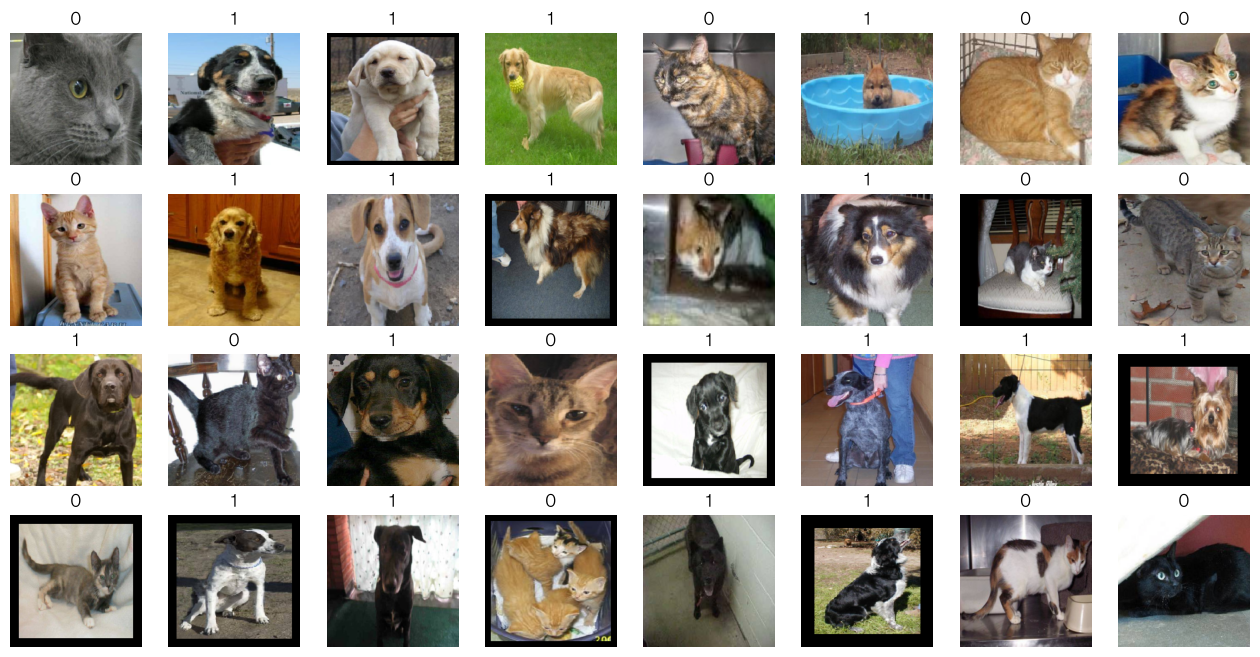

In [10]:
imgs, labels = next(iter(train_dataloader))

mean = torch.tensor([0.485, 0.456, 0.406]).view(3, 1, 1)
std = torch.tensor([0.229, 0.224, 0.225]).view(3, 1, 1)

fig, axes = plt.subplots(4, 8, figsize=(16, 8))

for ax, img, label in zip(axes.flatten(), imgs, labels):
    img = img * std + mean
    ax.imshow(img.permute(1, 2, 0))
    ax.set_title(label.item())
    ax.axis("off")

plt.show()

# ※※※ 전이학습
- 전이 학습(Transfer Learning)은 이미 학습된 모델(주로 대규모 데이터셋에서 사전 학습된 딥러닝 모델)을 새로운 문제에 적용하여 학습 시간을 단축하고 성능을 향상시키는 방법입니다. 기존 모델이 학습한 특징(Feature)을 활용해, 새로운 데이터셋에서 모델의 일부(주로 마지막 레이어)만 다시 학습하거나 추가 학습(Fine-tuning)을 진행합니다. 이는 특히 데이터가 적거나 학습 리소스가 제한된 상황에서 효과적이며, 이미지 분류(예: ResNet, VGG), 자연어 처리(예: BERT, GPT) 등 다양한 분야에서 널리 사용됩니다.

<img src="https://blog.kakaocdn.net/dna/bWCWsv/btrFi9EE3yn/AAAAAAAAAAAAAAAAAAAAAFKy2ApONEsfFIMDik5TezjkjZJlRI8kJ9_6SAbF_rb3/img.png?credential=yqXZFxpELC7KVnFOS48ylbz2pIh7yKj8&expires=1793458799&allow_ip=&allow_referer=&signature=CffUwEfCxzfe6AdgRwUWE7g37vI%3D" />

#### 즉 학습이 많이 된 모델은 다른 모델도 잘 맞춘다.

## ※ 이미지넷
- 이미지넷(ImageNet)은 컴퓨터 비전 연구와 딥러닝 모델 개발에 폭넓게 활용되는 대규모 이미지 데이터셋입니다. 스탠포드 대학교의 페이페이 리(Fei-Fei Li) 교수 연구팀이 2009년에 처음 공개했으며, 약 1,400만 장에 달하는 이미지가 2만 2천여 개의 카테고리로 세분화되어 있습니다.

- 이 가운데 실제로 연구 현장에서 가장 자주 쓰이는 버전은 ILSVRC(ImageNet Large Scale Visual Recognition Challenge)로, 전체 데이터셋의 일부인 1,000개 클래스와 약 120만 장의 이미지로 구성됩니다. 방대한 양의 레이블링된 데이터를 제공함으로써, 모델이 이미지 속 객체를 인식하고 시각적 특징을 학습하는 데 필요한 기반을 마련해주었습니다. 실제로 ResNet, VGG, Inception과 같이 딥러닝 역사에 한 획을 그은 모델들 상당수가 이미지넷 챌린지를 무대로 탄생했습니다.
무엇보다 이미지넷은 전이 학습(Transfer Learning)의 발전에 결정적인 역할을 했으며, 오늘날까지도 딥러닝 연구를 평가하는 대표적인 벤치마크로 자리매김하고 있습니다.

## 기존 학습되어있는 모델의 가중치
- https://docs.pytorch.org/vision/main/models/generated/torchvision.models.alexnet.html

<img src="https://resources-public-blog.modulabs.co.kr/blog/prd/content/259481/Untitled-4.png" />

<img src="https://www.researchgate.net/publication/375660065/figure/fig1/AS:11431281205053411@1700064568770/A-simple-representation-of-the-architecture-of-AlexNet-In-2014-Szegedy-et-al-2014.png" />

In [11]:
if torch.cuda.is_available():
    device = torch.device("cuda")
elif torch.mps.is_available():
    device = torch.device("mps")
elif torch.xpu.is_available():
    device = torch.device("xpu")
else:
    device = torch.device("cpu")

print(f"현재 선택된 장치: {device}")

현재 선택된 장치: mps


In [12]:
base_path = r"/Users/kdt_0900_lyn/ml/resoce/dataset/test_set"
model_weight_path = os.path.join(base_path, "weights")
os.makedirs(model_weight_path, exist_ok=True)

# Pytorch Hub 기본 캐시 경로를 변경 

torch.hub.set_dir(model_weight_path)

model = models.alexnet(weights="IMAGENET1K_V1").to(device)

In [13]:
model
# 

AlexNet(
  (features): Sequential(
    (0): Conv2d(3, 64, kernel_size=(11, 11), stride=(4, 4), padding=(2, 2))
    (1): ReLU(inplace=True)
    (2): MaxPool2d(kernel_size=3, stride=2, padding=0, dilation=1, ceil_mode=False)
    (3): Conv2d(64, 192, kernel_size=(5, 5), stride=(1, 1), padding=(2, 2))
    (4): ReLU(inplace=True)
    (5): MaxPool2d(kernel_size=3, stride=2, padding=0, dilation=1, ceil_mode=False)
    (6): Conv2d(192, 384, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (7): ReLU(inplace=True)
    (8): Conv2d(384, 256, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (9): ReLU(inplace=True)
    (10): Conv2d(256, 256, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (11): ReLU(inplace=True)
    (12): MaxPool2d(kernel_size=3, stride=2, padding=0, dilation=1, ceil_mode=False)
  )
  (avgpool): AdaptiveAvgPool2d(output_size=(6, 6))
  (classifier): Sequential(
    (0): Dropout(p=0.5, inplace=False)
    (1): Linear(in_features=9216, out_features=4096, bias=True)
 

In [14]:
# (features): Sequential(
#     (0): Conv2d(3, 64, kernel_size=(11, 11), stride=(4, 4), padding=(2, 2))
#     (1): ReLU(inplace=True)
#     (2): MaxPool2d(kernel_size=3, stride=2, padding=0, dilation=1, ceil_mode=False)
#     (3): Conv2d(64, 192, kernel_size=(5, 5), stride=(1, 1), padding=(2, 2))
#     (4): ReLU(inplace=True)
#     (5): MaxPool2d(kernel_size=3, stride=2, padding=0, dilation=1, ceil_mode=False)
#     (6): Conv2d(192, 384, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
#     (7): ReLU(inplace=True)
#     (8): Conv2d(384, 256, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
#     (9): ReLU(inplace=True)
#     (10): Conv2d(256, 256, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
#     (11): ReLU(inplace=True)
#     (12): MaxPool2d(kernel_size=3, stride=2, padding=0, dilation=1, ceil_mode=False)
# )

In [15]:
list(model.parameters())

[Parameter containing:
 tensor([[[[ 1.1864e-01,  9.4069e-02,  9.5435e-02,  ...,  5.5822e-02,
             2.1575e-02,  4.9963e-02],
           [ 7.4882e-02,  3.8940e-02,  5.2979e-02,  ...,  2.5709e-02,
            -1.1299e-02,  4.1590e-03],
           [ 7.5425e-02,  3.8779e-02,  5.4930e-02,  ...,  4.3596e-02,
             1.0225e-02,  1.3251e-02],
           ...,
           [ 9.3155e-02,  1.0374e-01,  6.7547e-02,  ..., -2.0277e-01,
            -1.2839e-01, -1.1220e-01],
           [ 4.3544e-02,  6.4916e-02,  3.6164e-02,  ..., -2.0248e-01,
            -1.1376e-01, -1.0719e-01],
           [ 4.7369e-02,  6.2543e-02,  2.4758e-02,  ..., -1.1844e-01,
            -9.5567e-02, -8.3890e-02]],
 
          [[-7.2634e-02, -5.7996e-02, -8.0661e-02,  ..., -6.0304e-04,
            -2.5309e-02,  2.5471e-02],
           [-6.9042e-02, -6.7562e-02, -7.6367e-02,  ..., -3.9616e-03,
            -3.0402e-02,  1.0477e-02],
           [-9.9517e-02, -8.5592e-02, -1.0521e-01,  ..., -2.6587e-02,
            -2.2

## ※ 모델 프리징(Model Freezing)
모델 프리징은 전이 학습(Transfer Learning) 과정에서 사전 학습된 네트워크의 일부 혹은 전체 층에 대해 가중치 업데이트를 막아, 학습 중에도 값이 변하지 않도록 만드는 방법이다.
보통 컨볼루션 층처럼 앞쪽에 위치한 계층들은 이미 엣지나 텍스처 같은 범용적인 특징을 추출하도록 학습되어 있기 때문에 그대로 고정해 두고, 새로운 문제에 맞춰 조정이 필요한 분류기(classifier) 부분, 즉 상위 계층만 별도로 학습시킨다. 이렇게 하면 학습해야 할 파라미터 수가 줄어들어 연산 부담이 적어지고, 데이터가 충분하지 않은 상황에서도 과적합을 억제하는 효과를 얻을 수 있다. 또한 처음에는 일부 층을 고정해 두었다가, 어느 정도 학습이 진행된 뒤 동결을 해제하고 파인튜닝을 진행하여 모델의 성능을 한층 더 끌어올리는 방식도 가능하다.

In [16]:
# 더이상 학습하지 못하게 막는다 

In [17]:
for pram in model.parameters():
    pram.requires_grad = False

In [18]:
model.features
model.classifier

Sequential(
  (0): Dropout(p=0.5, inplace=False)
  (1): Linear(in_features=9216, out_features=4096, bias=True)
  (2): ReLU(inplace=True)
  (3): Dropout(p=0.5, inplace=False)
  (4): Linear(in_features=4096, out_features=4096, bias=True)
  (5): ReLU(inplace=True)
  (6): Linear(in_features=4096, out_features=1000, bias=True)
)

In [19]:
model.classifier = nn.Sequential(
    nn.Linear(256 * 6 * 6, 128),
    nn.ReLU(), 
    nn.Linear(128, 1),  # 형태로 하겠다 
    nn.Sigmoid()  #로 받음 
).to(device)

In [20]:
model
# 출력층 바뀜 

AlexNet(
  (features): Sequential(
    (0): Conv2d(3, 64, kernel_size=(11, 11), stride=(4, 4), padding=(2, 2))
    (1): ReLU(inplace=True)
    (2): MaxPool2d(kernel_size=3, stride=2, padding=0, dilation=1, ceil_mode=False)
    (3): Conv2d(64, 192, kernel_size=(5, 5), stride=(1, 1), padding=(2, 2))
    (4): ReLU(inplace=True)
    (5): MaxPool2d(kernel_size=3, stride=2, padding=0, dilation=1, ceil_mode=False)
    (6): Conv2d(192, 384, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (7): ReLU(inplace=True)
    (8): Conv2d(384, 256, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (9): ReLU(inplace=True)
    (10): Conv2d(256, 256, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (11): ReLU(inplace=True)
    (12): MaxPool2d(kernel_size=3, stride=2, padding=0, dilation=1, ceil_mode=False)
  )
  (avgpool): AdaptiveAvgPool2d(output_size=(6, 6))
  (classifier): Sequential(
    (0): Linear(in_features=9216, out_features=128, bias=True)
    (1): ReLU()
    (2): Linear(in_featur

## 전이학습 
- features : 프리징
- classifier : 학습 

In [21]:
# 손실함수 
criterion = nn.BCELoss() 
optimizer = optim.Adam(model.classifier.parameters(), lr=0.001)
# 분류기만 학습시키기 
                       

In [27]:
def train_one_epoch_binary(model, dataloader, criterion, optimizer, device="cpu"):
    model.train()
    sum_losses = 0.0
    sum_accs = 0.0

    for i, (X_batch, y_batch) in enumerate(dataloader, 1):
        X_batch, y_batch = X_batch.to(device), y_batch.to(device)
        batch_loss = 0.0
        
        # 학습
        optimizer.zero_grad()
        y_pred = model(X_batch)
        loss = criterion(y_pred, y_batch)
        loss.backward()
        optimizer.step()

        batch_loss += loss.item()
        sum_losses += batch_loss

        # 이진 분류 정확도
        y_pred_tag = (y_pred >= 0.5).float()
        acc = (y_batch == y_pred_tag).float().mean().item() * 100
        sum_accs += acc

        if i % 20 == 0:
            print(f"[Batch {i}/{len(dataloader)}] Batch Loss: {batch_loss:.4f}, Batch Accuracy: {acc:.2f}%")

    avg_loss = sum_losses / len(dataloader)
    avg_acc = sum_accs / len(dataloader)

    return avg_loss, avg_acc

In [28]:
@torch.no_grad()
def evaluate_binary(model, dataloader, criterion, device="cpu"):
    model.eval()
    sum_losses = 0.0
    sum_accs = 0.0

    for X_batch, y_batch in dataloader:
        X_batch, y_batch = X_batch.to(device), y_batch.to(device)

        y_pred = model(X_batch)
        loss = criterion(y_pred, y_batch)
        sum_losses += loss.item()

        y_pred_tag = (y_pred >= 0.5).float()
        acc = (y_batch == y_pred_tag).float().mean().item() * 100
        sum_accs += acc

    avg_loss = sum_losses / len(dataloader)
    avg_acc = sum_accs / len(dataloader)
    
    return avg_loss, avg_acc

In [24]:
# 최고 모델 학습 , 전이 

In [29]:
def train_model_binary(model, model_name, train_loader, val_loader, criterion, optimizer, epochs, device, save_base_dir):
    save_dir = os.path.join(save_base_dir, model_name)
    os.makedirs(save_dir, exist_ok=True)

    history = {"train_loss": [], "val_loss": [], "train_acc": [], "val_acc": []}
    best_val_acc = 0.0

    # 학습
    print(f"========================={model_name} 학습 시작 ============================")
    for epoch in range(epochs):
        train_loss, train_acc = train_one_epoch_binary(model, train_loader, criterion, optimizer, device)
        val_loss, val_acc = evaluate_binary(model, val_loader, criterion, device)

        print(f"[Epoch: {epoch + 1}] | Train Loss: {train_loss:.4f} | Train Accuracy: {train_acc:.2f}%")
        print(f"[Epoch: {epoch + 1}] | Validation Loss: {val_loss:.4f} | Validation Accuracy: {val_acc:.2f}%")

        history["train_loss"].append(train_loss)
        history["val_loss"].append(val_loss)
        history["train_acc"].append(train_acc)
        history["val_acc"].append(val_acc)

        if val_acc > best_val_acc:
            best_val_acc = val_acc
            torch.save(model.state_dict(), os.path.join(save_dir, "best_model.pth"))

    torch.save(model.state_dict(), os.path.join(save_dir, f"last_model_{epochs}.pth"))
    print(f"========================={model_name} 학습 종료 ============================")
    return history

In [26]:
optimizer1 = optim.Adam(model.classifier.parameters(), lr=0.001)

history1 = train_model_binary(
    model=model,
    model_name="Alexnet",
    train_loader=train_dataloader,
    val_loader=test_dataloader,
    criterion=criterion,
    optimizer=optimizer,
    epochs=10,
    device=device,
    save_base_dir=os.path.join(base_path, "weights")
)

=========================Alexnet 학습 시작 ============================


ValueError: Using a target size (torch.Size([32])) that is different to the input size (torch.Size([32, 1])) is deprecated. Please ensure they have the same size.

## ResNet
- AlexNet은 단순 직렬 구조라 층을 더 깊게 쌓으면 오차가 커지는 한계가 발생
    1. CNN은 층을 쌓아 특징을 추출하고, 역전파로 gradient를 구해 가중치를 업데이트하는 구조
    2. 층을 깊게 쌓을수록 더 좋은 특징을 뽑을 거라 기대했지만
    3. 실제로는 gradient가 소실되며 학습 자체가 잘 안 되는 역설이 발생
    4. 이를 해결하기 위해 Skip Connection으로 지름길을 뚫어 gradient가 잘 흐르도록 만든 것 = ResNet
- [ResNet 논문](https://arxiv.org/pdf/1512.03385)

#### 기울기 소실
1. Chain Rule의 곱셈 누적 층이 깊어질수록 1보다 작은 미분값들이 계속 곱해져서 gradient가 점점 작아짐
2. ReLU의 0 미분 구간 음수 입력을 받은 뉴런은 gradient가 아예 0이 되어버려서, 그 경로는 완전히 끊김

<img src="https://media.licdn.com/dms/image/v2/D4D12AQEKnou6Clky8Q/article-cover_image-shrink_720_1280/article-cover_image-shrink_720_1280/0/1722845401189?e=2147483647&v=beta&t=wf7ytelj0GhvhMaY3pmexiIeodgI5e_IzGOZBOcel4k" />

## ResNet의 Skip Connection: Forward / Backward 관점 정리

### 1) Forward 관점 — 정보 보존
- **AlexNet (plain) 방식**: `out = F(x)`
  - 다음 레이어는 오직 이 블록의 결과값(F(x))만 받음
  - 원본 입력(x) 정보는 이 시점에서 사라짐
  - 블록이 이상한 값을 뱉으면, 그 이상한 값만 그대로 다음 층으로 전달됨

- **ResNet 방식**: `out = F(x) + x`
  - 다음 레이어는 "원본 정보(x) + 이 블록이 추가한 변화(F(x))"를 합친 값을 받음
  - 원본 신호가 사라지지 않고 계속 다음 층까지 보존되며 이어짐
  - 이 블록이 별로 유용한 특징을 못 뽑아냈어도(F(x) ≈ 0), 최소한 원본 정보(x)는 손실 없이 다음 층에 그대로 전달됨

### 2) Backward 관점 — 기울기 보존 (핵심)
- **AlexNet (plain) 방식**: `out = F(x)`
  - 미분: `d(out)/dx = dF(x)/dx`
  - F(x) 쪽 미분값이 작아지면, 전달되는 gradient도 그대로 작아짐 (소실 위험)

- **ResNet 방식**: `out = F(x) + x`
  - 미분: `d(out)/dx = dF(x)/dx + 1`
  - **"+1"이 무조건 보장됨** → F(x) 쪽 gradient가 아무리 작아지거나 0이 되어도, identity 경로로 최소한의 gradient가 항상 흐름

### 한 줄 요약
> Skip Connection은 forward에서는 "원본 정보를 보존한 채 변화량만 추가"하고, backward에서는 미분식에 "+1"이라는 항을 만들어 gradient가 절대 완전히 죽지 않도록 보장하는 구조다.

# 2. Horse vs Human 데이터셋
- Horse vs Human 데이터셋은 컴퓨터 비전과 이미지 분류 모델을 학습시키기 위해 제공되는 소규모 데이터셋입니다.
말(Horse)과 사람(Human)의 3D 렌더링 이미지로 구성되어 있습니다.
이 데이터를 통해 이 두 클래스를 분류하는 이미지 분류 모델을 학습시킬 수 있습니다
- [데이터셋 케글 주소](https://www.kaggle.com/datasets/sanikamal/horses-or-humans-dataset)

In [ ]:
from kaggle.api.kaggle_api_extended import KaggleApi

api = KaggleApi()
api.authenticate()

# output_dir = r"/Users/kdt_0900_lyn/ml/resoce/dataset"
output_dir = r"/Users/kdt_0900_lyn/ml/resoce/dataset"
os.makedirs(output_dir, exist_ok=True)
#https://www.kaggle.com/datasets/sanikamal/horses-or-humans-dataset
api.dataset_download_files(r"sanikamal/horses-or-humans-dataset", path=output_dir, unzip=True)

print("다운로드 완료")

In [ ]:
mean = [0.485, 0.456, 0.406]
std = [0.229, 0.224, 0.225]

train_transform = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.RandomHorizontalFlip(),  # 이미지를 일정한 확률로 좌우 반전시키는 기능
    transforms.RandomRotation(10),
    transforms.ToTensor(),   # 이미지를 PyTorch가 계산할 수 있는 텐서(Tensor) 형태로 변환하는 기능
    transforms.Normalize(mean=mean, std=std)
])

test_transform = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.ToTensor(),
    transforms.Normalize(mean=mean, std=std)
])

# AdaptiveAvgPool2d
target_transform = lambda y: torch.tensor([y], dtype=torch.float32)

In [ ]:
train_path = os.path.join(base_path, r"horse-or-human", r"train")
test_path = os.path.join(base_path, r"horse-or-human", r"validation")

train_dataset = ImageFolder(train_path, transform=train_transform, target_transform=target_transform)
test_dataset = ImageFolder(test_path, transform=test_transform, target_transform=target_transform)


In [ ]:
print(len(train_dataset), len(test_dataset))

In [ ]:
train_dataloader = DataLoader(train_dataset, batch_size=32, shuffle=True)
test_dataloader = DataLoader(test_dataset, batch_size=32, shuffle=False)

In [ ]:
imgs, labels = next(iter(train_dataloader))train_path = os.path.join(base_path, r"horse-or-human", r"train")
test_path = os.path.join(base_path, r"horse-or-human", r"validation")

train_dataset = ImageFolder(train_path, transform=train_transform, target_transform=target_transform)
test_dataset = ImageFolder(test_path, transform=test_transform, target_transform=target_transform)


mean = torch.tensor([0.485, 0.456, 0.406]).view(3, 1, 1)
std = torch.tensor([0.229, 0.224, 0.225]).view(3, 1, 1)

fig, axes = plt.subplots(4, 8, figsize=(16, 8))

for ax, img, label in zip(axes.flatten(), imgs, labels):
    img = img * std + mean
    ax.imshow(img.permute(1, 2, 0))
    ax.set_title(label.item())
    ax.axis("off")

plt.show()

In [ ]:
model2 = models.resnet18(weights="IMAGENET1K_V1").to(device)
model2

# 모델 프리징 
z

In [ ]:
for param in model2.paramiiters():
    param.requires_grad = False 

In [ ]:
model2.fc = nn.Sequential()

In [ ]:
optimiser12 = optim.Adem(model2.fc.paramiiters(), lr=0.001)
criterion = nn.BCELoss()

history2 = train_model_binary(
    mode= model2,
    model_name=""
    train_loader = train_dataloader,

)




In [ ]:
img = Image.open(img_path).convert("RGB")
img_tensor = 

img_tensor = test_transform()

## 모델 프리징 

In [ ]:
for param in model2.parameters():
    param.requires_grad = False

In [ ]:
model2.fc = nn.Sequential(
    nn.Linear(512, 128),
    nn.ReLU(),
    nn.Linear(128, 1),
    nn.Sigmoid()
).to(device)

In [ ]:
optimizer2 = optim.Adam(model2.fc.parameters(), lr=0.001)
criterion = nn.BCELoss()

history2 = train_model_binary(
    model=model2,
    model_name="Resnet",
    train_loader=train_dataloader,
    val_loader=test_dataloader,
    criterion=criterion,
    optimizer=optimizer2,
    epochs=10,
    device=device,
    save_base_dir=os.path.join(base_path, "weights")
)

In [ ]:
img_path = r"D:\kdt_0900_ksh\ml\resource\profile.jpg"
img = Image.open(img_path).convert("RGB")

img_tensor = test_transform(img).unsqueeze(0).to(device)

model2.eval()
with torch.no_grad():
    pred = model2(img_tensor)
    prob = pred.item() * 100
    pred_label = int(prob >= 0.5)

class_names = train_dataset.classes
print(f"확률: {prob:.2f}%")
print(f"예측 결과: {class_names[pred_label]}")
plt.imshow(img)
plt.show()

### 다중 클래스 분류 

In [ ]:
from kaggle.api.kaggle_api_extended import KaggleApi

api = KaggleApi()
api.authenticate()
os.makedirs(base_path, exist_ok=True)
api.dataset_download_files(
    dataset='puneet6060/intel-image-classification',
    path=base_path,
    unzip=True
)

print(f"다운로드 완료: {base_path}")

In [ ]:
mean = [0.485, 0.456, 0.406]
std = [0.229, 0.224, 0.225]

train_transform = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.RandomHorizontalFlip(),
    transforms.RandomRotation(10),
    transforms.ToTensor(),
    transforms.Normalize(mean=mean, std=std)
])

test_transform = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.ToTensor(),
    transforms.Normalize(mean=mean, std=std)
])

# AdaptiveAvgPool2d
target_transform = lambda y: torch.tensor([y], dtype=torch.float32)

In [ ]:
train_path = os.path.join(base_path, r"seg_train", r"seg_train")
test_path = os.path.join(base_path, r"seg_test", r"seg_test")

train_dataset = ImageFolder(train_path, transform=train_transform)
test_dataset = ImageFolder(test_path, transform=test_transform)

In [ ]:
train_path = os.path.join(base_path, r"")
train_path = os.path.join(base_path, r"")

train_dataset = ImageFolder(train_path, transforms= train_transform, target_transform=target_transform)
test_dataset = ImageFolder(test_path, transforms= train_transform, target_transform=target_transform)

In [ ]:
print(len(train_dataset), len(test_dataset))

In [ ]:
class_to_index = train_dataset.class_to_idx
class_dict = dict(enumerate(train_dataset.classes))

In [ ]:
train_dataloader = DataLoader(train_dataset, batch_size=32, shuffle=True)
test_dataloader = DataLoader(test_dataset, batch_size=32, shuffle=False)

In [ ]:
len(class_dict)

In [ ]:
model3 = models.resnet18(weights="IMAGENET1K_V1").to(device)
model3.fc

### 모델 프리징 

In [ ]:
for param in model3.parameters():
    param.requires_grad = False

### 전이 학습 

In [ ]:
model3.fc = nn.Sequential(
    nn.Linear(512, 128),
    nn.ReLU(),
    nn.Linear(128, 6)
).to(device)

In [ ]:
def train_one_epoch_multiclass(model, dataloader, criterion, optimizer, device="cpu"):
    model.train()
    sum_losses = 0.0
    sum_accs = 0.0

    for i, (X_batch, y_batch) in enumerate(dataloader, 1):
        X_batch, y_batch = X_batch.to(device), y_batch.to(device)
        batch_loss = 0.0
        
        # 학습
        optimizer.zero_grad()
        y_pred = model(X_batch)
        loss = criterion(y_pred, y_batch)
        loss.backward()
        optimizer.step()

        batch_loss += loss.item()
        sum_losses += batch_loss

        # 다중 클래스의 정확도 계산
        y_pred_index = y_pred.argmax(dim=1)
        acc = (y_batch == y_pred_index).float().mean().item() * 100
        sum_accs += acc

        if i % 20 == 0:
            print(f"[Batch {i}/{len(dataloader)}] Batch Loss: {batch_loss:.4f}, Batch Accuracy: {acc:.2f}%")

    avg_loss = sum_losses / len(dataloader)
    avg_acc = sum_accs / len(dataloader)

    return avg_loss, avg_acc

In [ ]:
@torch.no_grad()
def evaluate_multiclass(model, dataloader, criterion, device="cpu"):
    model.eval()
    sum_losses = 0.0
    sum_accs = 0.0

    for X_batch, y_batch in dataloader:
        X_batch, y_batch = X_batch.to(device), y_batch.to(device)

        y_pred = model(X_batch)
        loss = criterion(y_pred, y_batch)
        sum_losses += loss.item()

        # 다중 클래스 정확도 계산
        y_pred_index = y_pred.argmax(dim=1)
        acc = (y_batch == y_pred_index).float().mean().item() * 100
        sum_accs += acc

    avg_loss = sum_losses / len(dataloader)
    avg_acc = sum_accs / len(dataloader)
    
    return avg_loss, avg_acc

In [ ]:
def train_model_multiclass(model, model_name, train_loader, val_loader, criterion, optimizer, epochs, device, save_base_dir):
    save_dir = os.path.join(save_base_dir, model_name)
    os.makedirs(save_dir, exist_ok=True)

    history = {"train_loss": [], "val_loss": [], "train_acc": [], "val_acc": []}
    best_val_acc = 0.0

    # 학습
    print(f"========================={model_name} 학습 시작 ============================")
    for epoch in range(epochs):
        train_loss, train_acc = train_one_epoch_multiclass(model, train_loader, criterion, optimizer, device)
        val_loss, val_acc = evaluate_multiclass(model, val_loader, criterion, device)

        print(f"[Epoch: {epoch + 1}] | Train Loss: {train_loss:.4f} | Train Accuracy: {train_acc:.2f}%")
        print(f"[Epoch: {epoch + 1}] | Validation Loss: {val_loss:.4f} | Validation Accuracy: {val_acc:.2f}%")

        history["train_loss"].append(train_loss)
        history["val_loss"].append(val_loss)
        history["train_acc"].append(train_acc)
        history["val_acc"].append(val_acc)

        if val_acc > best_val_acc:
            best_val_acc = val_acc
            torch.save(model.state_dict(), os.path.join(save_dir, "best_model.pth"))

    torch.save(model.state_dict(), os.path.join(save_dir, f"last_model_{epochs}.pth"))
    print(f"========================={model_name} 학습 종료 ============================")
    return history

In [ ]:
criterion = nn.CrossEntropyLoss()
optimizer3 = optim.Adam(model3.fc.parameters(), lr=0.001)

In [ ]:
history3 = train_model_multiclass(
    model=model3,
    model_name="Resnet-multiclass",
    train_loader=train_dataloader,
    val_loader=test_dataloader,
    criterion=criterion,
    optimizer=optimizer3,
    epochs=10,
    device=device,
    save_base_dir=os.path.join(base_path, "weigths")
)